In [86]:
# Librerías
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay
import statsmodels.api as sm
import statsmodels.formula.api as smf
from pathlib import Path

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

from sklearn.preprocessing import StandardScaler

from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

# 1. Carga y preparación de datos

In [87]:
df = pd.read_csv('data/datos_preprocesados.csv')
df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Personas_Cargo,Fiador,Impago,Prima,Estudios_encoded,Estado_Civil_Divorciado,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial
0,KG9CT9,34,56572,73978,763,86,1,13.91,60,0.55,...,0,0,0,800.00,2,0,1,0,0,1
1,V5O0K9,37,68698,150000,824,162,2,10.53,24,0.37,...,0,0,0,580.00,2,0,0,0,1,0
2,YE5GD0,40,50000,7490,671,167,2,9.24,60,0.10,...,1,0,0,130.00,1,0,0,0,0,0
3,Q6HQ3D,38,63033,11801,649,196,1,7.63,48,0.10,...,1,0,0,168.08,1,0,1,0,0,1
4,XO8CO4,19,22301,40000,788,17,4,8.40,36,0.50,...,1,1,0,293.94,0,0,1,0,1,0


In [88]:
# Resultados del análisis financiero
finanzas = pd.read_csv(
    "data/clientes_clasificados_frances_aleman.csv"
)
finanzas.head()

,ID,Monto_Inicial,Ratio_Interes,Duracion,Ingresos,Esfuerzo_Inicial_Fr,Esfuerzo_Inicial_Al,Ahorro_Intereses_Al,Intereses_Totales_Fr,Sobreesfuerzo_Inicial_Al,Sistema_Recomendado,Ambos_Superan_Limite,Diferencia_Esfuerzo,Ahorro_Intereses_Pct
0,000AIY,53671,16.75,48,50294,36.785600,44.553312,1978.435520,20332.799374,325.557721,Francés,True,7.767711,9.730266
1,000OJE,40000,8.83,36,19018,80.060587,88.680899,232.600374,5677.767041,136.617582,Francés,True,8.620312,4.096688
2,000PLV,26187,8.43,48,69183,11.180782,12.653852,246.691329,4753.801366,84.926147,Alemán,False,1.473070,5.189349
3,000Q3U,78378,14.47,36,50507,64.071137,74.182384,1218.728598,18703.227523,425.573952,Francés,True,10.111247,6.516141
4,000TF1,3913,8.42,36,16000,9.253408,10.211300,20.695805,528.635813,12.771889,Alemán,False,0.957892,3.914946


In [89]:
columnas_financieras = [
    "ID",
    "Esfuerzo_Inicial_Fr",
    "Esfuerzo_Inicial_Al",
    "Ahorro_Intereses_Pct",
    "Sobreesfuerzo_Inicial_Al",
    "Sistema_Recomendado",
    "Ambos_Superan_Limite"
]

In [90]:
# describe de varibales numéricas contínuas
df[['Ratio_Interes', 'Duracion', 'Ratio_Deuda_Ingresos', 'Prima', 'Ingresos', 'Monto_Inicial', 'Scoring_Crediticio', 'Meses_Empleo', 'Num_Creditos']].describe()

,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Prima,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos
count,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000
mean,10.676211,37.255523,0.321933,386.809055,41509.970740,45190.765937,692.053285,212.770601,2.001025
std,3.809254,14.166838,0.181164,267.648386,16036.504202,46648.083692,87.828224,150.688070,1.001298
min,2.010000,12.000000,0.100000,10.000000,16000.000000,3000.000000,398.000000,0.000000,1.000000
25%,7.960000,24.000000,0.140000,138.880000,30484.250000,15126.000000,635.000000,70.000000,1.000000
50%,10.590000,36.000000,0.290000,340.095000,39090.500000,40000.000000,704.000000,208.000000,2.000000
75%,13.270000,48.000000,0.550000,621.670000,50096.750000,47626.500000,761.000000,336.000000,3.000000
max,24.440000,60.000000,0.550000,800.000000,120000.000000,400000.000000,845.000000,639.000000,4.000000


In [91]:
df = df.merge(
    finanzas[columnas_financieras],
    on="ID",
    how="left",
    validate="one_to_one"
)

df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Esfuerzo_Inicial_Fr,Esfuerzo_Inicial_Al,Ahorro_Intereses_Pct,Sobreesfuerzo_Inicial_Al,Sistema_Recomendado,Ambos_Superan_Limite
0,KG9CT9,34,56572,73978,763,86,1,13.91,60,0.55,...,1,0,0,1,36.439698,44.343385,10.107178,372.606139,Francés,True
1,V5O0K9,37,68698,150000,824,162,2,10.53,24,0.37,...,0,0,1,0,121.549207,132.165420,3.238250,607.760466,Francés,True
2,YE5GD0,40,50000,7490,671,167,2,9.24,60,0.10,...,0,0,0,0,3.752495,4.380152,6.990729,26.152370,Alemán,False
3,Q6HQ3D,38,63033,11801,649,196,1,7.63,48,0.10,...,1,0,0,1,5.445751,6.108969,4.723142,34.837147,Alemán,False
4,XO8CO4,19,22301,40000,788,17,4,8.40,36,0.50,...,1,0,1,0,67.845326,74.854640,3.906059,130.262266,Francés,True


In [92]:
print("Dimensiones:", df.shape)

print("\nValores ausentes en variables financieras:")
print(df[columnas_financieras[1:]].isna().sum())

Dimensiones: (178606, 27)

Valores ausentes en variables financieras:
Esfuerzo_Inicial_Fr         0
Esfuerzo_Inicial_Al         0
Ahorro_Intereses_Pct        0
Sobreesfuerzo_Inicial_Al    0
Sistema_Recomendado         0
Ambos_Superan_Limite        0
dtype: int64


In [93]:
# Convertir el booleano a 0 y 1
df["Ambos_Superan_Limite"] = (
    df["Ambos_Superan_Limite"].astype(int)
)

In [94]:
# Para que solo aparezca el esfuerzo del sistema elegido
df["Esfuerzo_Sistema_Elegido"] = np.where(
    df["Sistema_Recomendado"] == "Alemán",
    df["Esfuerzo_Inicial_Al"],
    df["Esfuerzo_Inicial_Fr"]
)

In [95]:
#Transformar las variables financieras
df = pd.get_dummies(
    df,
    columns=["Sistema_Recomendado"],
    drop_first=True,
    dtype=int
)

In [96]:
resumen = pd.DataFrame({
        "Frecuencia": df['Impago'].value_counts(),
        "Porcentaje": (
            df['Impago']
            .value_counts(normalize=True)
            .mul(100)
            .round(2)
        )
    })
resumen

,Frecuencia,Porcentaje
Impago,,
0,157832,88.37
1,20774,11.63


El 88.37% de los clientes han pagado y el 11.63% no. Un modelo de clasificación que sea útil debe de ser capaz de predecir correctamente un porcentaje de observaciones por encima del porcentaje de la clase mayoritaria. En este caso, el umbral de referencia que se tiene que superar es del 88.37%.

# 2. División train/test y escalado

Antes de ajustar la regresión logística se excluyen algunas columnas que no deben utilizarse directamente como variables predictoras:
- Impago: es la variable objetivo que el modelo debe predecir. Por tanto, se guarda por separado en y.
- ID: es únicamente un identificador de cada cliente. No representa una característica económica o financiera y podría introducir relaciones artificiales.
- Prima: se excluye porque el objetivo final es calcular la prima a partir del riesgo de impago estimado. Utilizarla para predecir el impago produciría una relación circular y podría generar fuga de información.
- Esfuerzo_Inicial_Fr y Esfuerzo_Inicial_Al: representan el esfuerzo de cuota bajo los dos sistemas posibles. Se sustituyen por Esfuerzo_Sistema_Elegido, que recoge únicamente el esfuerzo correspondiente al sistema recomendado para cada cliente. De este modo se evita introducir información redundante.

In [97]:
columnas_excluir = [
    "Impago",
    "ID",
    "Prima",
    "Esfuerzo_Inicial_Fr",
    "Esfuerzo_Inicial_Al"
]

X = df.drop(columns=columnas_excluir)
y = df["Impago"]

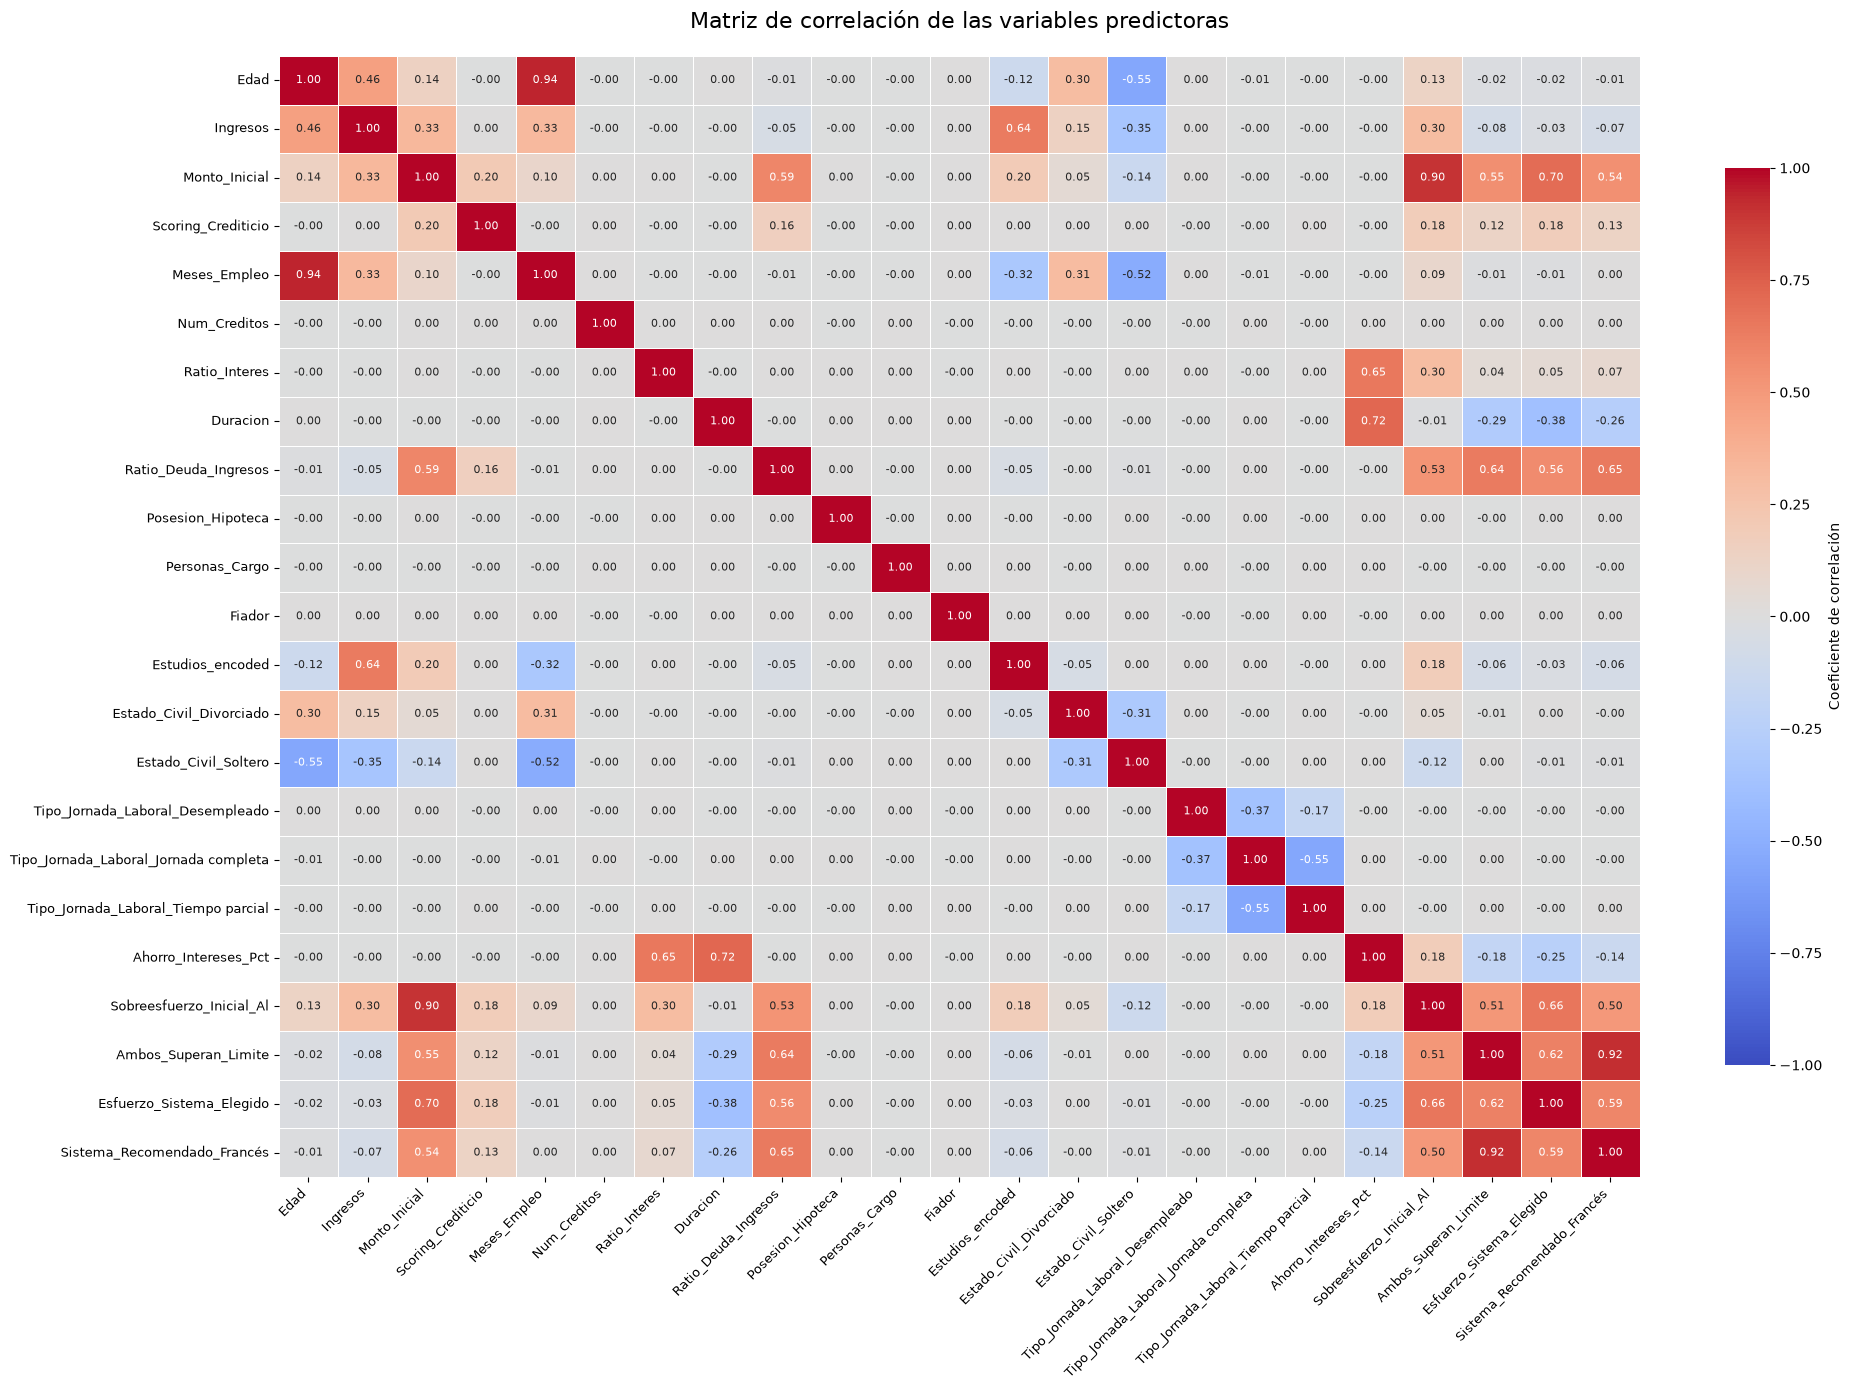

In [98]:
# Matriz de correlación de las variables que realmente entran al modelo
correlacion = X.corr()

plt.figure(figsize=(20, 14))

sns.heatmap(
    correlacion,
    annot=True,          # Mostrar los valores
    fmt=".2f",           # Dos decimales
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 8},
    cbar_kws={
        "label": "Coeficiente de correlación",
        "shrink": 0.8
    }
)

plt.title(
    "Matriz de correlación de las variables predictoras",
    fontsize=16,
    pad=20
)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=9
)

plt.yticks(
    rotation=0,
    fontsize=9
)

plt.tight_layout()
plt.show()

In [99]:
columnas_excluir = [
    "Impago",
    "ID",
    "Prima",
    "Esfuerzo_Inicial_Fr",
    "Esfuerzo_Inicial_Al",
    "Edad",
    "Sobreesfuerzo_Inicial_Al",
    "Ambos_Superan_Limite"
]

X = df.drop(columns=columnas_excluir)
y = df["Impago"]

Se eliminaron las variables con correlaciones superiores a 0,90 para reducir la multicolinealidad. Se mantuvo Meses_Empleo frente a Edad por su mayor interpretación crediticia, Monto_Inicial frente a Sobreesfuerzo_Inicial_Al por ser una variable original, y Sistema_Recomendado_Francés frente a Ambos_Superan_Limite para conservar explícitamente el sistema de amortización asignado.

In [101]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.8,
    random_state=42,
    shuffle=True,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [102]:
# Función para evaluar las métricas
def evaluar_modelo(modelo, X_test, y_test):
    
    prediccion = modelo.predict(X_test)
    probabilidad = modelo.predict_proba(X_test)[:, 1]

    print("Cantidad de predicciones:")
    print(pd.Series(prediccion).value_counts())

    print("Matriz de confusión:")
    print(confusion_matrix(y_test, prediccion))

    print("\nInforme de clasificación:")
    print(classification_report(y_test, prediccion))

    print("ROC-AUC:", round(roc_auc_score(y_test, probabilidad), 3))
    print(
        "PR-AUC:",
        round(average_precision_score(y_test, probabilidad), 3)
    )

# 3. Análisis estadístico con statsmodels

In [103]:
# Recuperamos los nombres de las variables después del escalado
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

# Añadimos la constante
X_train_stats = sm.add_constant(X_train_scaled_df)

# Ajustamos la regresión logística
modelo_stats = sm.Logit(
    y_train,
    X_train_stats
).fit()

print(modelo_stats.summary())

Optimization terminated successfully.
         Current function value: 0.335932
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                 Impago   No. Observations:               142884
Model:                          Logit   Df Residuals:                   142863
Method:                           MLE   Df Model:                           20
Date:                Mon, 12 Oct 2026   Pseudo R-squ.:                 0.06558
Time:                        19:48:58   Log-Likelihood:                -47999.
converged:                       True   LL-Null:                       -51368.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                            coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------
const                                    -2.2141      

In [104]:
import numpy as np

resultados_stats = pd.DataFrame({
    'Coeficiente': modelo_stats.params,
    'Odds_ratio': np.exp(modelo_stats.params),
    'P_valor': modelo_stats.pvalues
})

resultados_stats['Significativa_5%'] = (
    resultados_stats['P_valor'] < 0.05
)

resultados_stats

,Coeficiente,Odds_ratio,P_valor,Significativa_5%
const,-2.214119,0.109250,0.000000e+00,True
Ingresos,-0.002286,0.997717,9.005255e-01,False
Monto_Inicial,-0.041089,0.959743,2.610174e-02,True
Scoring_Crediticio,-0.101435,0.903540,4.985748e-33,True
Meses_Empleo,-0.575006,0.562701,5.646205e-283,True
Num_Creditos,-0.001818,0.998184,8.300639e-01,False
Ratio_Interes,0.386523,1.471854,7.253669e-52,True
Duracion,-0.047132,0.953962,1.295841e-01,False
Ratio_Deuda_Ingresos,0.019489,1.019680,1.272313e-01,False
Posesion_Hipoteca,-0.009611,0.990435,2.572195e-01,False


# 4. Predicción con sklearn

## 1. class_weight='balanced'

In [105]:
modelo_class_weight = LogisticRegression(
    class_weight='balanced',
    max_iter=2000,
    random_state=42
)

modelo_class_weight.fit(X_train_scaled, y_train)

evaluar_modelo(
    modelo_class_weight,
    X_test_scaled,
    y_test
)

Cantidad de predicciones:
0    21153
1    14569
Name: count, dtype: int64
Matriz de confusión:
[[19704 11863]
 [ 1449  2706]]

Informe de clasificación:
              precision    recall  f1-score   support

           0       0.93      0.62      0.75     31567
           1       0.19      0.65      0.29      4155

    accuracy                           0.63     35722
   macro avg       0.56      0.64      0.52     35722
weighted avg       0.84      0.63      0.69     35722

ROC-AUC: 0.688
PR-AUC: 0.223


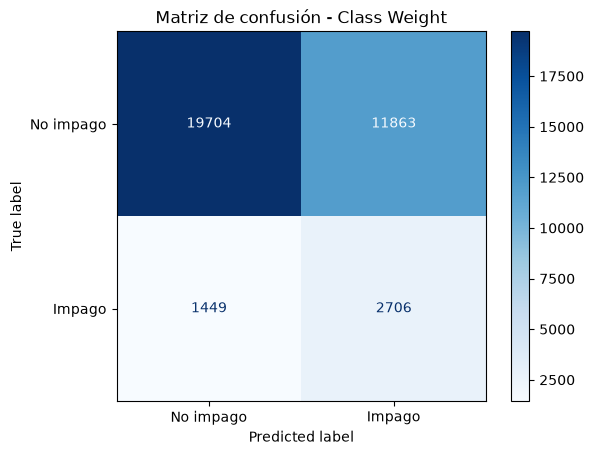

In [106]:
pred_class_weight = modelo_class_weight.predict(X_test_scaled)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_class_weight,
    display_labels=['No impago', 'Impago'],
    cmap='Blues',
    values_format='d'
)

plt.title("Matriz de confusión - Class Weight")
plt.show()

## 2. RandomOverSampler

Oversampler es una técnica de balanceado, duplica aleatoriamente observaciones de impago hasta igualar las dos clases

In [107]:
oversampler = RandomOverSampler(random_state=42)

X_train_over, y_train_over = oversampler.fit_resample(
    X_train_scaled,
    y_train
)

print("Distribución original:")
print(pd.Series(y_train).value_counts())

print("\nDistribución después del oversampling:")
print(pd.Series(y_train_over).value_counts())

Distribución original:
Impago
0    126265
1     16619
Name: count, dtype: int64

Distribución después del oversampling:
Impago
0    126265
1    126265
Name: count, dtype: int64


In [108]:
modelo_over = LogisticRegression(
    max_iter=2000,
    random_state=42
)

modelo_over.fit(X_train_over, y_train_over)

evaluar_modelo(
    modelo_over,
    X_test_scaled,
    y_test
)

Cantidad de predicciones:
0    21211
1    14511
Name: count, dtype: int64
Matriz de confusión:
[[19748 11819]
 [ 1463  2692]]

Informe de clasificación:
              precision    recall  f1-score   support

           0       0.93      0.63      0.75     31567
           1       0.19      0.65      0.29      4155

    accuracy                           0.63     35722
   macro avg       0.56      0.64      0.52     35722
weighted avg       0.84      0.63      0.69     35722

ROC-AUC: 0.688
PR-AUC: 0.223


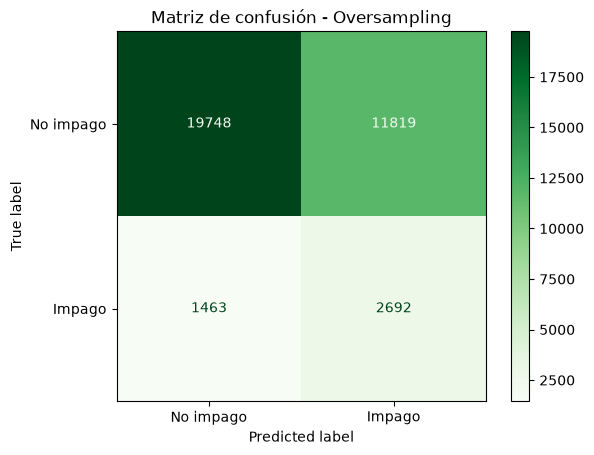

In [109]:
pred_over = modelo_over.predict(X_test_scaled)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_over,
    display_labels=['No impago', 'Impago'],
    cmap='Greens',
    values_format='d'
)

plt.title("Matriz de confusión - Oversampling")
plt.show()

## 3. RandomUnderSampler

RandomUnderSampler es una técnica de balanceado que reduce la clase mayoritaria hasta igualar las dos clases

In [110]:
undersampler = RandomUnderSampler(random_state=42)

X_train_under, y_train_under = undersampler.fit_resample(
    X_train_scaled,
    y_train
)

print("Distribución original:")
print(pd.Series(y_train).value_counts())

print("\nDistribución después del undersampling:")
print(pd.Series(y_train_under).value_counts())

Distribución original:
Impago
0    126265
1     16619
Name: count, dtype: int64

Distribución después del undersampling:
Impago
0    16619
1    16619
Name: count, dtype: int64


In [111]:
modelo_under = LogisticRegression(
    max_iter=2000,
    random_state=42
)

modelo_under.fit(X_train_under, y_train_under)

evaluar_modelo(
    modelo_under,
    X_test_scaled,
    y_test
)

Cantidad de predicciones:
0    21094
1    14628
Name: count, dtype: int64
Matriz de confusión:
[[19654 11913]
 [ 1440  2715]]

Informe de clasificación:
              precision    recall  f1-score   support

           0       0.93      0.62      0.75     31567
           1       0.19      0.65      0.29      4155

    accuracy                           0.63     35722
   macro avg       0.56      0.64      0.52     35722
weighted avg       0.84      0.63      0.69     35722

ROC-AUC: 0.688
PR-AUC: 0.223


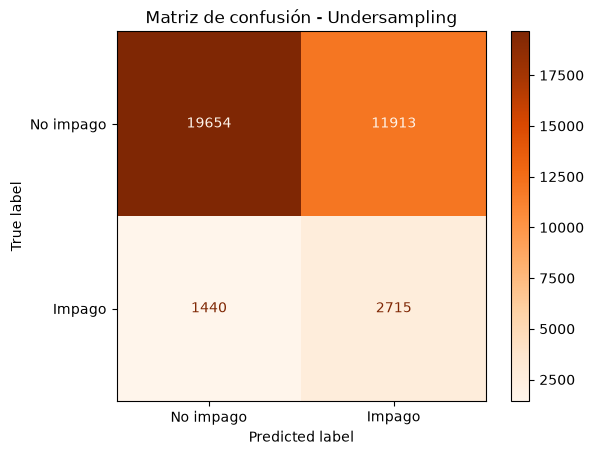

In [112]:
pred_under = modelo_under.predict(X_test_scaled)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_under,
    display_labels=['No impago', 'Impago'],
    cmap='Oranges',
    values_format='d'
)

plt.title("Matriz de confusión - Undersampling")
plt.show()

Resultados provisionales:
Los resultados obtenidos corresponden a un modelo inicial construido con las variables disponibles actualmente. El análisis estadístico y la comparación de las técnicas de balanceo son provisionales, ya que todavía deben incorporarse nuevas variables financieras, como el sistema de amortización.
Una vez añadidas estas variables, se volverán a ajustar los modelos utilizando la misma metodología y se compararán sus resultados. Por tanto, en esta fase no se extraen conclusiones definitivas sobre la significación de las variables ni se selecciona una técnica de balanceo final.